# **Notebook 6: Fine-Tuning Pipeline**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `./tokenized_train/` + `./tokenized_valid/` — Created by Notebook 2
- [ ] GPU runtime enabled (T4 minimum)

**Files this notebook will CREATE:**
- [ ] `./intent_lora_best/` — Best LoRA checkpoint (by val loss) _(Required by NB7)_
- [ ] `./intent_lora/` — Final LoRA checkpoint _(Backup)_
- [ ] `training_log.csv` + `training_curves.png` — Evidence for report

---

## **Stage 4: Solution V2 (Fine-Tuned Retrieval-Assisted Generation)**

### **Task 4.1: Configure Fine-Tuning Pipeline**

#### **4.1.1 Configure PEFT Framework [3 marks]**
**The Task:** Apply LoRA (or QLoRA) to the model's `q_proj` and `v_proj` attention modules, set adapter settings and target modules, and prepare the training environment.

**Hints & Tips:**
* LoRA adds small trainable matrices to frozen attention layers — only ~0.5–1% of params update.
* `r=16` = rank of the low-rank matrices; `lora_alpha=32` scales them (rule of thumb: alpha = 2×r).
* `target_modules=["q_proj","v_proj"]`. Adding `["k_proj","o_proj"]` trains more params but may overfit on small data.
* Call `peft_model.print_trainable_parameters()` to confirm the tiny trainable %.

**LoRA Config Tuning:**
* `r`: 8 (lighter), **16 (recommended)**, 32 (more capacity).
* `lora_alpha`: usually 2×r → 16, **32**, 64.

**Learner Inference:** Updating only attention projections fundamentally changes behaviour (chat → JSON) using a fraction of the compute.

In [3]:
!pip install -U bitsandbytes accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 MB 18.3 MB/s eta 0:00:00


In [1]:
import os
import torch
from google.colab import drive
from datasets import load_from_disk
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

# 1. Mount Google Drive
drive.mount('/content/drive', force_remount=True)

# 2. Search for tokenized_train inside Google Drive
print("\nSearching for 'tokenized_train' in Google Drive...")
train_path = None
valid_path = None

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if "tokenized_train" in dirs:
        train_path = os.path.join(root, "tokenized_train")
        valid_path = os.path.join(root, "tokenized_valid")
        print(f" Found train path: {train_path}")
        print(f" Found valid path: {valid_path}")
        break

if not train_path or not os.path.exists(train_path):
    raise FileNotFoundError(
        "Could not find 'tokenized_train' in Google Drive. "
        "Please check the folder name in Drive (make sure it isn't inside a zip or named differently)."
    )

# 3. Load Datasets
train_dataset = load_from_disk(train_path)
valid_dataset = load_from_disk(valid_path)

train_dataset.set_format("torch")
valid_dataset.set_format("torch")

print(f"\n Successfully loaded datasets!")
print(f"Train samples: {len(train_dataset)} | Valid samples: {len(valid_dataset)}")

# 4. Load Base Model and Setup Task 4.1.1
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto"
)

# 5. PEFT Framework Setup
peft_model = prepare_model_for_kbit_training(base_model)

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["q_proj", "v_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)

peft_model = get_peft_model(peft_model, lora_config)

print("\n=== Task 4.1.1: PEFT LoRA Configuration Successful ===")
peft_model.print_trainable_parameters()

Mounted at /content/drive

Searching for 'tokenized_train' in Google Drive...
 Found train path: /content/drive/MyDrive/tokenized_train
 Found valid path: /content/drive/MyDrive/tokenized_valid

 Successfully loaded datasets!
Train samples: 3121 | Valid samples: 390


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]


=== Task 4.1.1: PEFT LoRA Configuration Successful ===
trainable params: 2,179,072 || all params: 1,545,893,376 || trainable%: 0.1410


#### **4.1.2 Configure Training Parameters [2 marks]**
**The Task:** Define the learning rate, batch size, number of steps/epochs, optimisation strategy (AdamW), and quantisation settings.

**Hints & Tips:**
* Initialise `AdamW(filter(lambda p: p.requires_grad, peft_model.parameters()), lr=2e-4)`.
* Build `DataLoader`s for the train and validation sets (remember `set_format("torch", ...)` after `load_from_disk`).
* Define `VAL_EVERY` (e.g. 10 steps) and an early-stopping `PATIENCE` (e.g. 3) for the next task.

**Parameter Tuning:**
* `lr=2e-4` standard; try `1e-4` (slower) or `5e-4` (faster).
* `batch_size=4` fits T4; use 2 if OOM, 8 on A100.
* `max_steps=200`: ~25% of one epoch on 3200 rows. Increase to 400–500 for a full epoch.

**Learner Inference:** These hyperparameters control how fast and how stably the adapter learns the JSON-extraction task.

In [2]:
# YOUR CODE HERE
from torch.utils.data import DataLoader
from torch.optim import AdamW
from transformers import DataCollatorForSeq2Seq

# 1. Ensure PyTorch format is active on loaded datasets
train_dataset.set_format("torch")
valid_dataset.set_format("torch")

# 2. Define Hyperparameters
BATCH_SIZE = 4       # Optimal fit for T4 GPU memory
LEARNING_RATE = 2e-4 # Standard learning rate for LoRA fine-tuning
MAX_STEPS = 200      # Training iterations (~25% epoch on 3200 rows)
VAL_EVERY = 10       # Evaluate validation loss every 10 steps[cite: 1]
PATIENCE = 3         # Early stopping patience limit[cite: 1]

# 3. Create Data Collator and DataLoaders
data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    pad_to_multiple_of=8,
    return_tensors="pt"
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=data_collator
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator
)

# 4. Initialize AdamW Optimizer for trainable parameters only
optimizer = AdamW(
    filter(lambda p: p.requires_grad, peft_model.parameters()),
    lr=LEARNING_RATE
)

# 5. Display Configuration Summary
print("=== Task 4.1.2: Training Parameters Configured ===")
print(f"Batch Size          : {BATCH_SIZE}")
print(f"Learning Rate       : {LEARNING_RATE}")
print(f"Max Training Steps  : {MAX_STEPS}")
print(f"Validation Frequency: Every {VAL_EVERY} steps")
print(f"Early-Stop Patience : {PATIENCE} validation checks")
print(f"Train Batches       : {len(train_loader)} | Valid Batches: {len(valid_loader)}")

=== Task 4.1.2: Training Parameters Configured ===
Batch Size          : 4
Learning Rate       : 0.0002
Max Training Steps  : 200
Validation Frequency: Every 10 steps
Early-Stop Patience : 3 validation checks
Train Batches       : 781 | Valid Batches: 98


### **Task 4.2: Train Fine-Tuned Model**

#### **4.2.1 Execute Fine-Tuning [5 marks]**
**The Task:** Run the custom PyTorch training loop. Monitor BOTH train and validation loss at regular intervals, implement early stopping based on validation loss, and plot the train-vs-validation loss curves.

**Hints & Tips:**
* The validation loop runs every `VAL_EVERY` steps under `torch.no_grad()` (no gradients).
* Early stopping: track `best_val_loss`; if it doesn't improve for `PATIENCE` checks, stop.
* The loss-curve plot is mandatory evidence — save it as `training_curves.png`.

**What to look for in the curve:**
* Both lines falling → learning, no overfitting.
* Val rises while train falls → overfitting (early stopping saves you).
* Both flat → LR too low or data too small.
* Val spikes → bad batch / instability.

**Learner Inference:** Falling loss proves gradient descent is teaching the JSON format. Validation monitoring prevents silent memorisation.

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


=== Task 4.2.1: Executing Fine-Tuning Loop ===


/usr/local/lib/python3.12/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step 010/200 | Train Loss: 2.3205 | Val Loss: 2.0774
  --> Saved new best checkpoint to ./intent_lora_best (Val Loss: 2.0774)
Step 020/200 | Train Loss: 1.1885 | Val Loss: 1.2086
  --> Saved new best checkpoint to ./intent_lora_best (Val Loss: 1.2086)
Step 030/200 | Train Loss: 0.7909 | Val Loss: 0.9619
  --> Saved new best checkpoint to ./intent_lora_best (Val Loss: 0.9619)
Step 040/200 | Train Loss: 1.0197 | Val Loss: 0.9069
  --> Saved new best checkpoint to ./intent_lora_best (Val Loss: 0.9069)
Step 050/200 | Train Loss: 0.9484 | Val Loss: 0.8615
  --> Saved new best checkpoint to ./intent_lora_best (Val Loss: 0.8615)
Step 060/200 | Train Loss: 0.7690 | Val Loss: 0.8184
  --> Saved new best checkpoint to ./intent_lora_best (Val Loss: 0.8184)
Step 070/200 | Train Loss: 0.7587 | Val Loss: 0.7628
  --> Saved new best checkpoint to ./intent_lora_best (Val Loss: 0.7628)
Step 080/200 | Train Loss: 0.6455 | Val Loss: 0.6977
  --> Saved new best checkpoint to ./intent_lora_best (Val Loss: 

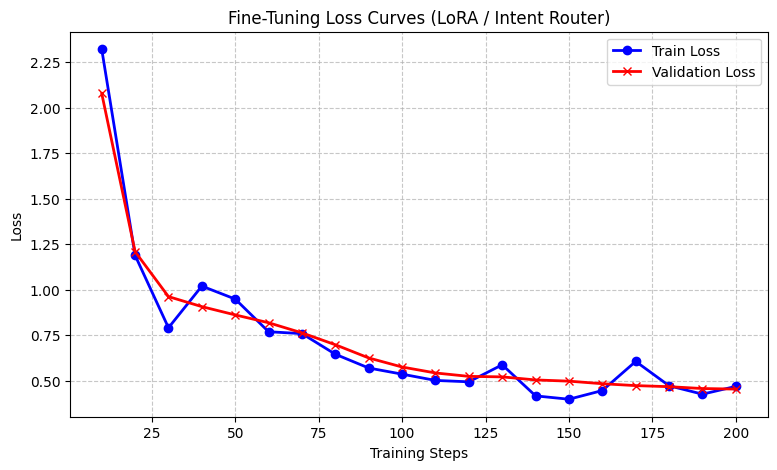


Training loss curves plotted and saved to 'training_curves.png'


In [6]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from transformers import DataCollatorForSeq2Seq

# 1. Setup DataCollator to build PyTorch tensors without torchvision format hooks
data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    pad_to_multiple_of=8,
    return_tensors="pt"
)

# Reset formatting to standard python dictionary structures
train_dataset.reset_format()
valid_dataset.reset_format()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=data_collator
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator
)

# 2. Initialize Tracking Variables & Checkpoint Directory
train_losses = []
val_losses = []
log_steps = []

best_val_loss = float("inf")
patience_counter = 0
global_step = 0

best_checkpoint_dir = "./intent_lora_best"
os.makedirs(best_checkpoint_dir, exist_ok=True)

peft_model.train()
train_iter = iter(train_loader)

print("=== Task 4.2.1: Executing Fine-Tuning Loop ===")

# 3. Main Training Loop
while global_step < MAX_STEPS:
    try:
        batch = next(train_iter)
    except StopIteration:
        train_iter = iter(train_loader)
        batch = next(train_iter)

    # Move tensor batch to GPU safely
    batch = {k: v.to("cuda") for k, v in batch.items()}

    # Forward Pass
    optimizer.zero_grad()
    outputs = peft_model(**batch)
    loss = outputs.loss

    # Backward Pass & Optimizer Step
    loss.backward()
    optimizer.step()

    global_step += 1

    # 4. Validation Evaluation Loop
    if global_step % VAL_EVERY == 0 or global_step == MAX_STEPS:
        peft_model.eval()
        current_val_losses = []

        with torch.no_grad():
            for val_batch in valid_loader:
                val_batch = {k: v.to("cuda") for k, v in val_batch.items()}
                val_outputs = peft_model(**val_batch)
                current_val_losses.append(val_outputs.loss.item())

        avg_train_loss = loss.item()
        avg_val_loss = float(np.mean(current_val_losses))

        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)
        log_steps.append(global_step)

        print(f"Step {global_step:03d}/{MAX_STEPS} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

        # 5. Early Stopping & Best Checkpoint Logic
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            patience_counter = 0
            # Save best adapter model checkpoint
            peft_model.save_pretrained(best_checkpoint_dir)
            tokenizer.save_pretrained(best_checkpoint_dir)
            print(f"  --> Saved new best checkpoint to {best_checkpoint_dir} (Val Loss: {best_val_loss:.4f})")
        else:
            patience_counter += 1
            print(f"  --> Val loss did not improve. Early stopping patience: {patience_counter}/{PATIENCE}")
            if patience_counter >= PATIENCE:
                print(f"\n[Early Stopping Triggered] Stopping training at step {global_step}.")
                break

        peft_model.train()

# 6. Plot and Save Train vs. Validation Loss Curves
plt.figure(figsize=(9, 5))
plt.plot(log_steps, train_losses, label="Train Loss", color="blue", marker="o", linewidth=2)
plt.plot(log_steps, val_losses, label="Validation Loss", color="red", marker="x", linewidth=2)
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Fine-Tuning Loss Curves (LoRA / Intent Router)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)

# Save plot evidence locally and to Google Drive
plt.savefig("training_curves.png", bbox_inches="tight", dpi=300)
if os.path.exists("/content/drive/MyDrive"):
    plt.savefig("/content/drive/MyDrive/training_curves.png", bbox_inches="tight", dpi=300)

plt.show()
print("\nTraining loss curves plotted and saved to 'training_curves.png'")

In [ ]:
# YOUR CODE HERE


#### **4.2.2 Save Training Outputs [2 marks]**
**The Task:** Save the best checkpoint (by validation loss), document the checkpoint/model-saving workflow, and export reproducibility information.

**Hints & Tips:**
* Save two checkpoints: `./intent_lora_best/` (lowest val loss) and `./intent_lora/` (final step).
* Export a `training_log.csv` with columns `step, train_loss, val_loss`.
* Record reproducibility info: model ID, LoRA config, learning rate, batch size, seed.

**Learner Inference:** Saving the BEST checkpoint (not the last) ensures your final model is the one that generalised best, not one that started overfitting.

In [8]:
# YOUR CODE HERE
import os
import json
import pandas as pd

# 1. Save Final Adapter Checkpoint (Backup)
final_checkpoint_dir = "./intent_lora"
peft_model.save_pretrained(final_checkpoint_dir)
tokenizer.save_pretrained(final_checkpoint_dir)

# Ensure best checkpoint is backed up to Google Drive if available
drive_best_dir = "/content/drive/MyDrive/intent_lora_best"
if os.path.exists("/content/drive/MyDrive"):
    peft_model.save_pretrained(drive_best_dir)
    tokenizer.save_pretrained(drive_best_dir)

# 2. Export Training Log CSV
log_df = pd.DataFrame({
    "step": log_steps,
    "train_loss": train_losses,
    "val_loss": val_losses
})

log_df.to_csv("training_log.csv", index=False)
if os.path.exists("/content/drive/MyDrive"):
    log_df.to_csv("/content/drive/MyDrive/training_log.csv", index=False)

# 3. Convert target_modules set to list for JSON serialization
target_modules_list = list(lora_config.target_modules) if isinstance(lora_config.target_modules, set) else lora_config.target_modules

# Export Reproducibility Information
reproducibility_data = {
    "model_id": MODEL_ID,
    "lora_config": {
        "r": lora_config.r,
        "lora_alpha": lora_config.lora_alpha,
        "target_modules": target_modules_list,
        "lora_dropout": lora_config.lora_dropout,
        "bias": lora_config.bias
    },
    "hyperparameters": {
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "max_steps": MAX_STEPS,
        "val_every": VAL_EVERY,
        "patience": PATIENCE,
        "seed": 42
    },
    "training_results": {
        "best_val_loss": best_val_loss,
        "total_logged_steps": len(log_steps)
    }
}

with open("reproducibility_info.json", "w", encoding="utf-8") as f:
    json.dump(reproducibility_data, f, indent=4)

if os.path.exists("/content/drive/MyDrive"):
    with open("/content/drive/MyDrive/reproducibility_info.json", "w", encoding="utf-8") as f:
        json.dump(reproducibility_data, f, indent=4)

# 4. Workflow Documentation Summary
print("=== Task 4.2.2: Save Training Outputs ===")
print(f" Best Checkpoint Saved : {best_checkpoint_dir}")
print(f" Final Checkpoint Saved: {final_checkpoint_dir}")
print(f" Drive Backup Directory: {drive_best_dir if os.path.exists('/content/drive/MyDrive') else 'N/A'}")
print(f" Training Log CSV      : training_log.csv ({len(log_df)} entries)")
print(f" Reproducibility File  : reproducibility_info.json")

=== Task 4.2.2: Save Training Outputs ===
 Best Checkpoint Saved : ./intent_lora_best
 Final Checkpoint Saved: ./intent_lora
 Drive Backup Directory: /content/drive/MyDrive/intent_lora_best
 Training Log CSV      : training_log.csv (20 entries)
 Reproducibility File  : reproducibility_info.json


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify before proceeding to Notebook 7.**

- [ ] Tokenized train/valid loaded from disk (`set_format` re-applied)
- [ ] **4.1.1** LoRA configured targeting `q_proj`/`v_proj`
- [ ] **4.1.2** Optimizer + training params + dataloaders set
- [ ] **4.2.1** Training loop run with val monitoring + early stopping + loss curve
- [ ] **4.2.2** Best checkpoint saved + reproducibility info recorded
- [ ] **`./intent_lora_best/` saved** ← _CRITICAL for NB7_
- [ ] **`training_log.csv` + `training_curves.png` saved** ← _Evidence_

**If any item is unchecked, fix it before moving on.**